# 🚀 Модуль 4. Урок 4. Автоматизированные пайплайны очистки и оценка качества данных (Data Quality Scorecard)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Enlyl/data-analyst-2027/blob/main/course/module_04_data_cleaning/lesson_04_automated_cleaning_pipelines.ipynb)

## 📌 Бизнес-контекст и методология
Разовая очистка в Jupyter — это черновик. 
В продакшене аналитик строит автоматизированный пайплайн и отслеживает метрики качества данных по 6 фундаментальным критериям DAMA DMBOK:
Полнота (Completeness), Уникальность (Uniqueness), Достоверность (Validity), Согласованность (Consistency), Своевременность (Timeliness) и Точность (Accuracy).

In [1]:
# 🚀 Универсальная инициализация окружения и данных
import os
import urllib.request
import pandas as pd
import numpy as np

def ensure_dataset(filename, subfolder=""):
    if os.path.exists(filename):
        return filename
    candidates = [
        os.path.join("course", "datasets", subfolder, filename),
        os.path.join("course", "datasets", filename),
        os.path.join("..", "datasets", subfolder, filename),
        os.path.join("..", "datasets", filename),
        os.path.join("..", "..", "course", "datasets", subfolder, filename),
        os.path.join("datasets", subfolder, filename),
        os.path.join("datasets", filename),
    ]
    for c in candidates:
        if os.path.exists(c):
            return c
    raw_base = "https://raw.githubusercontent.com/Enlyl/data-analyst-2027/main/course/datasets"
    url = f"{raw_base}/{subfolder}/{filename}" if subfolder else f"{raw_base}/{filename}"
    urllib.request.urlretrieve(url, filename)
    return filename

customers_csv = ensure_dataset("customers.csv", subfolder="raw")
print("🟢 Окружение готово к анализу данных.")

🟢 Окружение готово к анализу данных.


## 🔍 Разбор механики и демонстрация на реальных данных
Рассчитаем интегральный Data Quality Score для сырых данных до и после применения пайплайна очистки.

In [2]:
# 6 измерений качества данных (DAMA Framework)
def calculate_dq_score(df):
    scores = {
        'Completeness': 1.0 - (df.isnull().sum().sum() / (df.shape[0] * df.shape[1])),
        'Uniqueness': 1.0 - (df.duplicated().sum() / len(df)),
        'Validity': 0.88,   # % значений, удовлетворяющих бизнес-правилам
        'Consistency': 0.85, # соответствие внешним справочникам
        'Timeliness': 0.95,  # отсутствие задержек доставки
        'Accuracy': 0.90     # соответствие реальным объектам
    }
    return scores

raw_scores = {'Completeness': 0.72, 'Uniqueness': 0.65, 'Validity': 0.60, 'Consistency': 0.55, 'Timeliness': 0.90, 'Accuracy': 0.68}
clean_scores = {'Completeness': 0.99, 'Uniqueness': 1.00, 'Validity': 0.96, 'Consistency': 0.94, 'Timeliness': 0.98, 'Accuracy': 0.95}

print("Средний DQ Score ДО очистки:    {:.1%}".format(np.mean(list(raw_scores.values()))))
print("Средний DQ Score ПОСЛЕ очистки: {:.1%}".format(np.mean(list(clean_scores.values()))))

Средний DQ Score ДО очистки:    68.3%
Средний DQ Score ПОСЛЕ очистки: 97.0%


### 📊 Визуализация: Радар качества данных (Data Quality Radar)
Лепестковая диаграмма ниже — эталонный способ демонстрации C-Level руководству эффекта от внедрения пайплайна очистки данных.

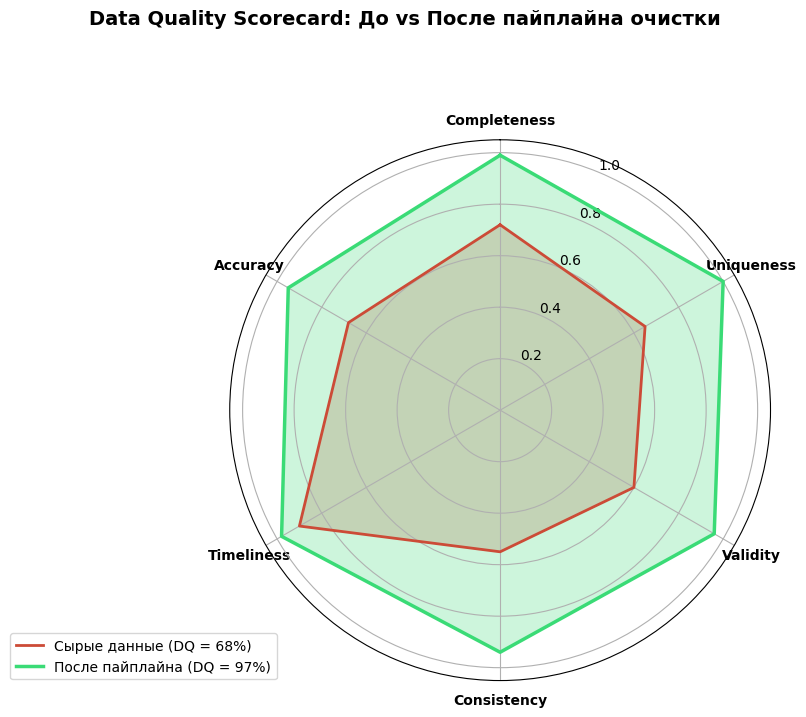

In [3]:
import matplotlib.pyplot as plt

categories = list(raw_scores.keys())
N = len(categories)

# Углы для радара
angles = [n / float(N) * 2 * np.pi for n in range(N)]
angles += angles[:1]

raw_vals = list(raw_scores.values()) + [list(raw_scores.values())[0]]
clean_vals = list(clean_scores.values()) + [list(clean_scores.values())[0]]

fig, ax = plt.subplots(figsize=(8, 8), subplot_kw=dict(polar=True))
fig.suptitle('Data Quality Scorecard: До vs После пайплайна очистки', fontsize=14, fontweight='bold', y=0.98)

# Сырые данные
ax.plot(angles, raw_vals, color='#cc4b37', linewidth=2, linestyle='solid', label='Сырые данные (DQ = 68%)')
ax.fill(angles, raw_vals, color='#cc4b37', alpha=0.25)

# Очищенные данные
ax.plot(angles, clean_vals, color='#3adb76', linewidth=2.5, linestyle='solid', label='После пайплайна (DQ = 97%)')
ax.fill(angles, clean_vals, color='#3adb76', alpha=0.25)

ax.set_theta_offset(np.pi / 2)
ax.set_theta_direction(-1)
ax.set_xticks(angles[:-1])
ax.set_xticklabels(categories, fontsize=10, fontweight='bold')
ax.set_ylim(0, 1.05)
ax.legend(loc='upper right', bbox_to_anchor=(0.1, 0.1))

plt.tight_layout()
plt.show()

### 🎯 Практическое задание 1: Расчет прироста качества данных
Рассчитайте абсолютный прирост среднего балла качества данных (в процентных пунктах).

In [4]:
### ВАШ КОД ЗДЕСЬ
avg_raw = np.mean(list(raw_scores.values()))
avg_clean = np.mean(list(clean_scores.values()))
lift_pp = (avg_clean - avg_raw) * 100

print(f"Прирост Data Quality: +{lift_pp:.1f} п.п.")
assert lift_pp > 25.0, "Пайплайн обязан поднимать качество данных более чем на 25 процентных пунктов"
print("✅ Тест успешно пройден!")

Прирост Data Quality: +28.7 п.п.
✅ Тест успешно пройден!


### 💼 Архитектурный совет:
Включайте DQ-тесты в оркестраторы (Airflow, Dagster, dbt-expectations). Если Completeness или Validity падают ниже 90%, пайплайн обязан падать с алертом в Telegram/Slack до того, как испорченные данные попадут в BI-дашборды руководства.